# 02 · Predictor de tiempo real (regresión)

**Objetivo:** predecir cuántas horas tomará realmente una subtarea.

**Pipeline:** datos → limpieza → preprocesamiento (one-hot para categóricas, escalado para numéricas) → comparación de modelos con validación cruzada de 5 pliegues → evaluación en un 20 % de prueba → modelo final.

La línea base es creerle al estudiante: `real = estimado`. El resultado que importa es cuánto reduce el modelo el error frente a esa línea base.

> Los datos de este notebook son sintéticos (ver notebook 01). Las métricas muestran que el pipeline funciona; las definitivas se obtienen al repetirlo con la encuesta.

In [1]:
import sys
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid", font_scale=0.95)
GRIS, OCRE, VERDE = "#4d4d4d", "#9a7b4f", "#5f7a6a"
plt.rcParams.update({"figure.dpi": 110, "axes.edgecolor": "#333333", "axes.titleweight": "bold"})
pd.set_option("display.precision", 3)

In [2]:
from ml import predictor_tiempo as pt
from ml.entrenar import cargar_tiempos

crudos = cargar_tiempos()
datos = pt.limpiar(crudos)
print(f"{len(crudos)} filas, {len(datos)} después de la limpieza")
print("Variables:", pt.VARIABLES, "· objetivo:", pt.OBJETIVO)
datos["fuente"].value_counts()

600 filas, 600 después de la limpieza
Variables: ['materia', 'tipo_tarea', 'dia_semana', 'franja', 'dificultad', 'estimado_h'] · objetivo: real_h


fuente
sintetico    600
Name: count, dtype: int64

## Comparación de modelos

Los tres modelos predicen el logaritmo de las horas: el error crece con el tamaño de la tarea, y trabajar en escala logarítmica estabiliza la varianza y evita predicciones negativas.

In [3]:
evaluacion = pt.evaluar(datos)
resultados = evaluacion["resultados"].set_index("modelo")
print("Mejor modelo por validación cruzada:", evaluacion["mejor"])
resultados

Mejor modelo por validación cruzada: Gradient Boosting


,MAE_cv,MAE,RMSE,R2
modelo,,,,
Línea base (real = estimado),NaN,2.356,3.425,0.114
Regresión lineal,1.308,1.202,2.712,0.445
Random Forest,1.221,1.200,1.729,0.774
Gradient Boosting,1.142,1.092,1.578,0.812


Error medio creyéndole al estimado: 2.36 h
Error medio con el modelo:          1.09 h
Reducción del error:                54%


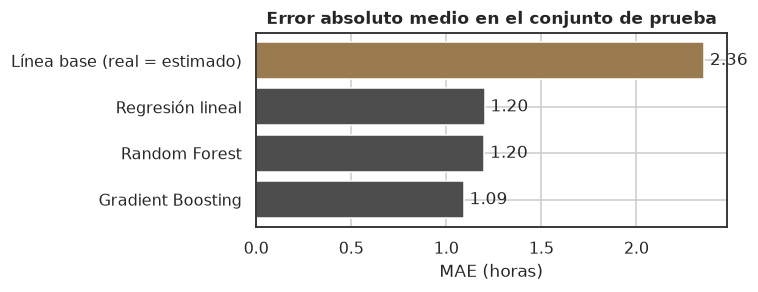

In [4]:
base = resultados.iloc[0]["MAE"]
mejor = resultados.loc[evaluacion["mejor"], "MAE"]
print(f"Error medio creyéndole al estimado: {base:.2f} h")
print(f"Error medio con el modelo:          {mejor:.2f} h")
print(f"Reducción del error:                {1 - mejor / base:.0%}")

fig, eje = plt.subplots(figsize=(7, 2.8))
colores = [OCRE] + [GRIS] * (len(resultados) - 1)
eje.barh(resultados.index[::-1], resultados["MAE"][::-1], color=colores[::-1])
eje.set(title="Error absoluto medio en el conjunto de prueba", xlabel="MAE (horas)")
for i, valor in enumerate(resultados["MAE"][::-1]):
    eje.text(valor + 0.03, i, f"{valor:.2f}", va="center")
plt.tight_layout()

## Predicho contra real

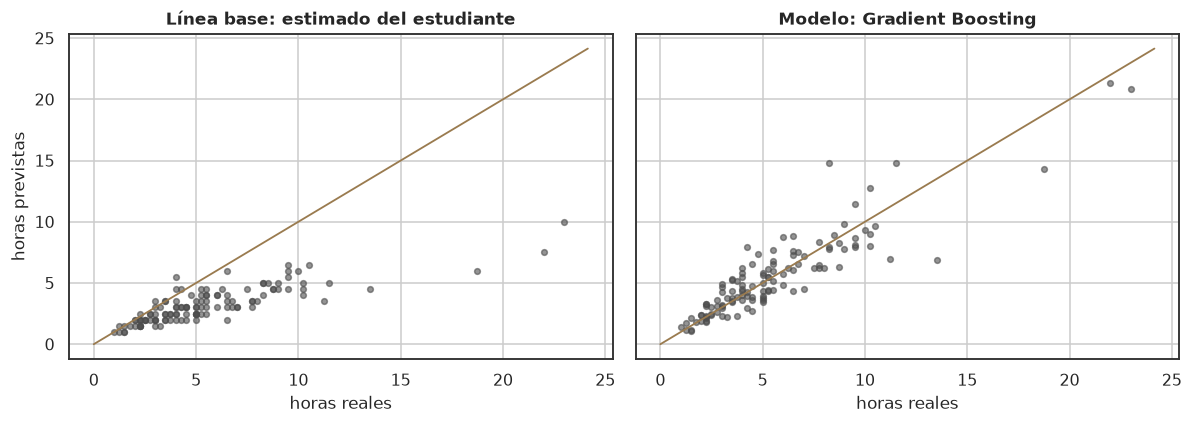

In [5]:
modelo = evaluacion["modelos"][evaluacion["mejor"]]
X_prueba, y_prueba = evaluacion["X_prueba"], evaluacion["y_prueba"]
predicho = modelo.predict(X_prueba)

fig, ejes = plt.subplots(1, 2, figsize=(11, 4), sharex=True, sharey=True)
tope = max(y_prueba.max(), predicho.max(), X_prueba["estimado_h"].max()) * 1.05
for eje, valores, titulo in [(ejes[0], X_prueba["estimado_h"], "Línea base: estimado del estudiante"), (ejes[1], predicho, f"Modelo: {evaluacion['mejor']}")]:
    eje.scatter(y_prueba, valores, s=14, color=GRIS, alpha=0.6)
    eje.plot([0, tope], [0, tope], color=OCRE, linewidth=1.2)
    eje.set(title=titulo, xlabel="horas reales")
ejes[0].set_ylabel("horas previstas")
plt.tight_layout()

## Error por tipo de tarea

,error_base,error_modelo
tipo_tarea,,
codigo,5.403,1.669
informe,2.500,1.153
estudio,2.143,1.412
presentacion,1.868,0.731
taller,1.660,0.951
lectura,0.518,0.324


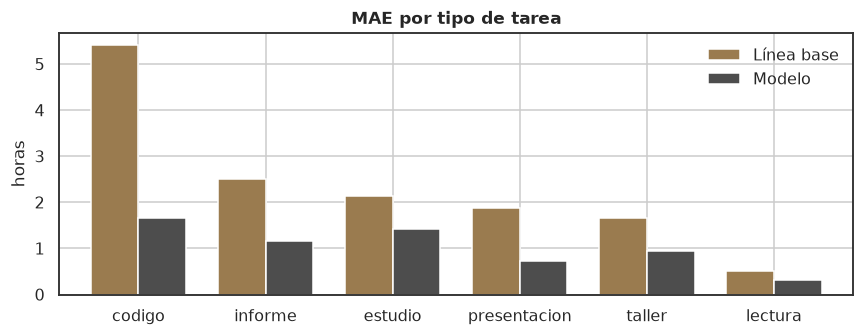

In [6]:
errores = X_prueba.assign(
    error_base=(y_prueba - X_prueba["estimado_h"]).abs(), error_modelo=np.abs(y_prueba - predicho)
)
por_tipo = errores.groupby("tipo_tarea")[["error_base", "error_modelo"]].mean().sort_values("error_base", ascending=False)
eje = por_tipo.plot.bar(figsize=(8, 3.2), color=[OCRE, GRIS], width=0.75)
eje.set(title="MAE por tipo de tarea", xlabel="", ylabel="horas")
eje.legend(["Línea base", "Modelo"], frameon=False)
plt.xticks(rotation=0)
plt.tight_layout()
por_tipo

## Importancia de las variables

Importancia por permutación: cuánto empeora el MAE al desordenar cada variable en el conjunto de prueba.

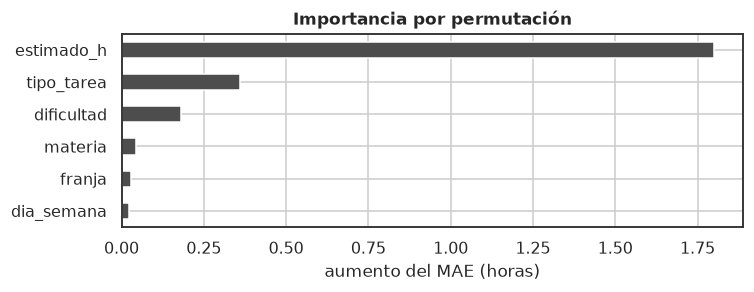

In [7]:
from sklearn.inspection import permutation_importance

importancia = permutation_importance(modelo, X_prueba, y_prueba, scoring="neg_mean_absolute_error", n_repeats=20, random_state=42)
orden = pd.Series(importancia.importances_mean, index=pt.VARIABLES).sort_values()
eje = orden.plot.barh(figsize=(7, 2.8), color=GRIS)
eje.set(title="Importancia por permutación", xlabel="aumento del MAE (horas)")
plt.tight_layout()

## Modelo final

El mejor modelo se reentrena con todos los datos y se guarda en `ml/modelos/`. Es el archivo que carga el skill `estimar_tiempo`. El bot repite este mismo proceso cada semana sumando el historial real del estudiante.

In [8]:
metricas = pt.entrenar_y_guardar(crudos, RAIZ / "ml" / "modelos")
metricas

{'modelo': 'Gradient Boosting',
 'filas': 600,
 'fuentes': {'sintetico': 600},
 'MAE': 1.0922950234017936,
 'RMSE': 1.5782737865613703,
 'R2': 0.8118899803084694,
 'MAE_linea_base': 2.35625,
 'reduccion_error': 0.5364265152671432}

In [9]:
predictor = pt.PredictorTiempo(RAIZ / "ml" / "modelos")
ejemplos = [
    ("Sistemas Operativos", "codigo", 4, 2.0, "martes", "noche"),
    ("Inteligencia Artificial", "informe", 3, 3.0, "jueves", "tarde"),
    ("Arquitectura de Software", "lectura", 2, 1.5, "sabado", "manana"),
]
pd.DataFrame(
    [(*e, predictor.predecir(*e)) for e in ejemplos],
    columns=["materia", "tipo", "dificultad", "estimado_h", "dia", "franja", "prediccion_h"],
)

,materia,tipo,dificultad,estimado_h,dia,franja,prediccion_h
0,Sistemas Operativos,codigo,4,2.0,martes,noche,4.75
1,Inteligencia Artificial,informe,3,3.0,jueves,tarde,5.50
2,Arquitectura de Software,lectura,2,1.5,sabado,manana,2.00
